# Wort-Embeddings: Ähnlichkeit, PCA und Analogien (Rechenbeispiel)

**Didaktisches Ziel:** *Bedeutung wird zu Geometrie: Ähnliche Wörter liegen nah beieinander, Beziehungen werden zu Richtungen.*

Dieses Notebook gehört zur Folie **„Wort-Embeddings visualisieren“** und verwendet genau die 8 Wörter und 7 Dimensionen aus der Tabelle dort:

1. Embedding-Matrix: Nachschlagen statt Rechnen
2. **Kosinus-Ähnlichkeit** von Hand und als Matrix
3. **PCA**: von 7 auf 2 Dimensionen (so entsteht das linke Diagramm der Folie)
4. **Analogie** König − Mann + Frau ≈ ?
5. Grenzen von handgemachten Dimensionen

> Echte Modelle haben hunderte bis tausende Dimensionen ohne Namen. Die benannten Dimensionen hier dienen nur der Anschauung.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=2, suppress=True)

words = ["Katze", "Kätzchen", "Hund", "Häuser", "Mann", "Frau", "König", "Königin"]
dims  = ["Lebewesen", "Katzenartig", "Menschlich", "Geschlecht", "Königlich", "Verb", "Plural"]

E = np.array([
    [ 0.6,  0.9,  0.1,  0.4, -0.7, -0.3, -0.2],   # Katze
    [ 0.5,  0.8, -0.1,  0.2, -0.6, -0.5, -0.1],   # Kätzchen
    [ 0.7, -0.1,  0.4,  0.3, -0.4, -0.1, -0.3],   # Hund
    [-0.8, -0.4, -0.5,  0.1, -0.9,  0.3,  0.8],   # Häuser
    [ 0.6, -0.2,  0.8,  0.9, -0.1, -0.9, -0.7],   # Mann
    [ 0.7,  0.3,  0.9, -0.7,  0.1, -0.5, -0.4],   # Frau
    [ 0.5, -0.4,  0.7,  0.8,  0.9, -0.7, -0.6],   # König
    [ 0.8, -0.1,  0.8, -0.9,  0.8, -0.5, -0.9],   # Königin
])
idx = {w: i for i, w in enumerate(words)}
print("Embedding-Matrix E:", E.shape, "(Wörter × Dimensionen)")

Embedding-Matrix E: (8, 7) (Wörter × Dimensionen)


## 1) Embedding = Zeile in einer Matrix

Im Modell bekommt jedes Token eine ID. Das Embedding ist einfach die passende **Zeile** der gelernten Matrix $E$.
Mathematisch ist das eine Multiplikation mit einem One-Hot-Vektor, praktisch nur ein Nachschlagen:

$$
x_{\text{Katze}} = \text{onehot}(\text{Katze})^\top \cdot E
$$

In [2]:
onehot = np.zeros(len(words))
onehot[idx["Katze"]] = 1.0

print("One-Hot 'Katze':  ", onehot)
print("onehot @ E:       ", onehot @ E)
print("Zeile E['Katze']: ", E[idx["Katze"]])

One-Hot 'Katze':   [1. 0. 0. 0. 0. 0. 0. 0.]
onehot @ E:        [ 0.6  0.9  0.1  0.4 -0.7 -0.3 -0.2]
Zeile E['Katze']:  [ 0.6  0.9  0.1  0.4 -0.7 -0.3 -0.2]


## 2) Kosinus-Ähnlichkeit

$$
\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}
$$

Wertebereich: $+1$ = gleiche Richtung, $0$ = unabhängig, $-1$ = entgegengesetzt. Die Länge der Vektoren spielt keine Rolle, nur die Richtung zählt.

**Von Hand für Katze und Kätzchen:**

- Skalarprodukt: $0.6\cdot0.5 + 0.9\cdot0.8 + 0.1\cdot(-0.1) + 0.4\cdot0.2 + (-0.7)(-0.6) + (-0.3)(-0.5) + (-0.2)(-0.1) = 1.68$
- Längen: $\lVert a \rVert = \sqrt{1.96} = 1.400$, $\lVert b \rVert = \sqrt{1.56} \approx 1.249$
- $\cos = 1.68 / (1.400 \cdot 1.249) \approx 0.96$

In [3]:
def cos_sim(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

a, b = E[idx["Katze"]], E[idx["Kätzchen"]]
print(f"Skalarprodukt: {a @ b:.3f}")
print(f"Längen:        {np.linalg.norm(a):.3f}, {np.linalg.norm(b):.3f}")
print(f"Kosinus:       {cos_sim(a, b):.3f}")

Skalarprodukt: 1.680
Längen:        1.400, 1.249
Kosinus:       0.961


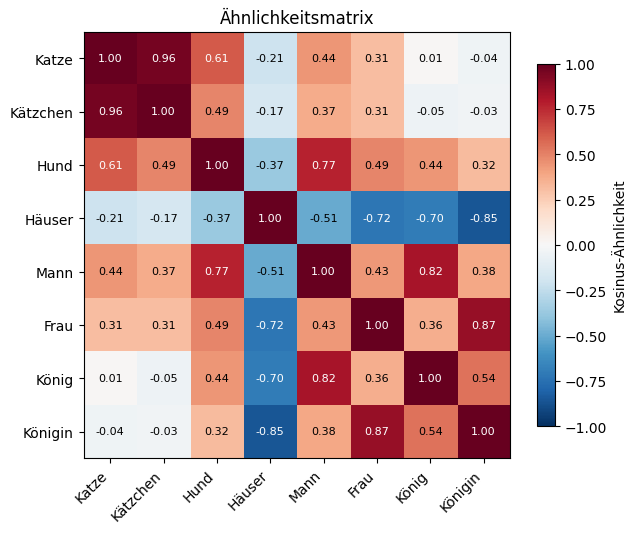

In [4]:
N = E / np.linalg.norm(E, axis=1, keepdims=True)   # alle Zeilen auf Länge 1
S = N @ N.T                                          # alle Kosinus-Werte auf einmal

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(S, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(words)), words, rotation=45, ha="right")
ax.set_yticks(range(len(words)), words)
for i in range(len(words)):
    for j in range(len(words)):
        ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(S[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Kosinus-Ähnlichkeit")
ax.set_title("Ähnlichkeitsmatrix")
plt.tight_layout()
plt.show()

In [5]:
def nachbarn(wort, n=3):
    s = S[idx[wort]]
    order = [i for i in np.argsort(s)[::-1] if i != idx[wort]]
    return [(words[i], round(float(s[i]), 2)) for i in order[:n]]

for w in words:
    print(f"{w:<9} → {nachbarn(w)}")

Katze     → [('Kätzchen', 0.96), ('Hund', 0.61), ('Mann', 0.44)]
Kätzchen  → [('Katze', 0.96), ('Hund', 0.49), ('Mann', 0.37)]
Hund      → [('Mann', 0.77), ('Katze', 0.61), ('Kätzchen', 0.49)]
Häuser    → [('Kätzchen', -0.17), ('Katze', -0.21), ('Hund', -0.37)]
Mann      → [('König', 0.82), ('Hund', 0.77), ('Katze', 0.44)]
Frau      → [('Königin', 0.87), ('Hund', 0.49), ('Mann', 0.43)]
König     → [('Mann', 0.82), ('Königin', 0.54), ('Hund', 0.44)]
Königin   → [('Frau', 0.87), ('König', 0.54), ('Mann', 0.38)]


**Beobachtung:** Katze und Kätzchen (0.96), Frau und Königin (0.87) sowie Mann und König (0.82) liegen sehr nah beieinander.
„Häuser“ ist zu allen Lebewesen negativ ähnlich, es zeigt also in die Gegenrichtung.

## 3) PCA: von 7 auf 2 Dimensionen

Sieben Dimensionen kann man nicht zeichnen. Die **Hauptkomponentenanalyse (PCA)** sucht die zwei Richtungen, entlang derer sich die Wörter am stärksten unterscheiden, und projiziert alle Vektoren darauf.

Rechenweg:
1. Mittelwert abziehen (zentrieren)
2. Singulärwertzerlegung $E_c = U \Sigma V^\top$
3. Die ersten zwei Zeilen von $V^\top$ sind die Hauptrichtungen; Projektion: $E_c \cdot V_{:,1:2}$

Erklärte Varianz je Komponente: [0.55 0.21 0.19 0.03 0.02 0.01 0.  ]
PC1 + PC2 erklären zusammen 76% der Unterschiede


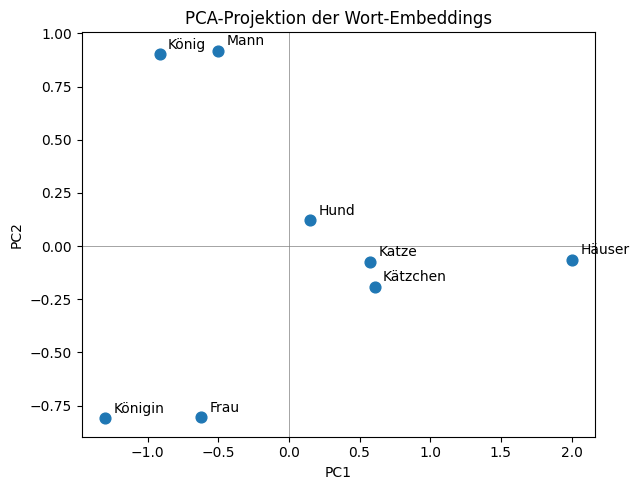

In [6]:
Ec = E - E.mean(axis=0)
U, sigma, Vt = np.linalg.svd(Ec, full_matrices=False)

erklaert = sigma**2 / np.sum(sigma**2)
print("Erklärte Varianz je Komponente:", erklaert)
print(f"PC1 + PC2 erklären zusammen {erklaert[:2].sum():.0%} der Unterschiede")

P = Ec @ Vt[:2].T     # 8 × 2

plt.figure(figsize=(6.5, 5))
plt.scatter(P[:, 0], P[:, 1], s=60)
for w, (x, y) in zip(words, P):
    plt.annotate(w, (x, y), textcoords="offset points", xytext=(6, 4))
plt.axhline(0, color="gray", lw=0.5)
plt.axvline(0, color="gray", lw=0.5)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA-Projektion der Wort-Embeddings")
plt.tight_layout()
plt.show()

**Was bedeuten die Achsen?** Jede Hauptkomponente ist eine Mischung der ursprünglichen Dimensionen. Die Gewichte zeigen, welche Eigenschaften eine Achse prägen:

In [7]:
for k in range(2):
    gewichte = Vt[k]
    order = np.argsort(np.abs(gewichte))[::-1][:3]
    print(f"PC{k+1}: " + ", ".join(f"{dims[i]} ({gewichte[i]:+.2f})" for i in order))

PC1: Königlich (-0.57), Plural (+0.47), Menschlich (-0.45)
PC2: Geschlecht (+0.93), Katzenartig (-0.30), Verb (-0.19)


> Die Vorzeichen einer PCA sind willkürlich. Ein anderes Programm kann das Bild gespiegelt zeigen, ohne dass sich etwas an den Abständen ändert.

Eine 2D-Projektion **verliert Information**. Zwei Wörter, die im Bild nah beieinander liegen, können im Originalraum weiter auseinander sein. Bei echten Embeddings mit 768 Dimensionen ist der Verlust viel größer als hier.

## 4) Analogie: König − Mann + Frau ≈ ?

Wenn Beziehungen als **Richtungen** im Raum gespeichert sind, dann ist der Vektor $\text{Frau} - \text{Mann}$ ungefähr die Richtung „männlich → weiblich“.
Addiert man diese Richtung zu „König“, sollte man in der Nähe von „Königin“ landen.

In [8]:
ziel = E[idx["König"]] - E[idx["Mann"]] + E[idx["Frau"]]
print("König − Mann + Frau =", ziel)

ergebnis = sorted(((w, cos_sim(ziel, E[i])) for w, i in idx.items()), key=lambda t: -t[1])
for w, s in ergebnis:
    print(f"  {w:<9} {s:+.3f}")

König − Mann + Frau = [ 0.6  0.1  0.8 -0.8  1.1 -0.3 -0.3]
  Königin   +0.921
  Frau      +0.798
  König     +0.500
  Mann      +0.203
  Hund      +0.097
  Kätzchen  -0.156
  Katze     -0.168
  Häuser    -0.825


In [9]:
richtung_mf = E[idx["Frau"]] - E[idx["Mann"]]
richtung_kk = E[idx["Königin"]] - E[idx["König"]]
print("Frau − Mann:      ", richtung_mf)
print("Königin − König:  ", richtung_kk)
print(f"Kosinus der beiden Richtungen: {cos_sim(richtung_mf, richtung_kk):.2f}")

Frau − Mann:       [ 0.1  0.5  0.1 -1.6  0.2  0.4  0.3]
Königin − König:   [ 0.3  0.3  0.1 -1.7 -0.1  0.2 -0.3]
Kosinus der beiden Richtungen: 0.91


Beide Differenzvektoren zeigen fast in dieselbe Richtung. Den größten Anteil hat die Dimension „Geschlecht“. Genau das zeigen die parallelen Pfeile im rechten Diagramm der Folie.

> Bei echten Embeddings (z. B. word2vec) funktioniert das nur näherungsweise. Die Eingabewörter selbst werden bei der Suche meist ausgeschlossen, weil sonst oft „König“ gewinnt.

## 5) Grenzen: handgemachte Dimensionen

Die Nachbarschaftsliste aus Abschnitt 2 zeigt etwas Überraschendes: **Hund liegt näher an Mann (0.77) als an Katze (0.61).**
Der Grund steht in der Tabelle: Hund hat „Menschlich = 0.4“ und „Katzenartig = −0.1“. Die Ähnlichkeit hängt vollständig davon ab, welche Dimensionen es gibt und wie sie belegt sind.

In echten Modellen werden die Werte nicht von Hand gesetzt, sondern **aus Textdaten gelernt**: Wörter, die in ähnlichen Kontexten vorkommen, bekommen ähnliche Vektoren (*distributional semantics*).
Hund und Katze würden dort sehr nah beieinander liegen, weil sie in ähnlichen Sätzen auftauchen.

In [10]:
# Experiment: eine zusätzliche Dimension "Haustier" einfügen
haustier = np.array([0.9, 0.9, 0.9, 0.0, 0.0, 0.0, 0.0, 0.0])   # Katze, Kätzchen, Hund
E2 = np.column_stack([E, haustier])

def cos_m(M, w1, w2):
    return cos_sim(M[idx[w1]], M[idx[w2]])

for w1, w2 in [("Hund", "Katze"), ("Hund", "Mann")]:
    print(f"{w1}–{w2}: vorher {cos_m(E, w1, w2):.2f}, mit 'Haustier' {cos_m(E2, w1, w2):.2f}")

Hund–Katze: vorher 0.61, mit 'Haustier' 0.74
Hund–Mann: vorher 0.77, mit 'Haustier' 0.57


## 6) Aufgaben

1. **Von Hand:** Berechne die Kosinus-Ähnlichkeit von Mann und König. Vergleiche mit der Matrix.
2. **Neues Wort:** Füge „Löwe“ als Zeile hinzu (katzenartig, königlich, kein Haustier). Wo landet er in der PCA?
3. **Analogie:** Funktioniert auch Kätzchen − Katze + Hund? Welches Wort fehlt im Vokabular, damit das Ergebnis Sinn ergibt?
4. **Dimensionen:** Ändere bei Hund „Menschlich“ auf −0.2. Wie verändern sich die Nachbarn?

---

### Take-away
**Embeddings übersetzen Wörter in Vektoren. Ähnlichkeit wird zum Winkel, Beziehungen werden zu Richtungen.** Welche Ähnlichkeiten entstehen, hängt davon ab, woraus die Vektoren gelernt wurden.